**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 6**
Ingeniería de características (FE)

---

Equipo:

José Antonio Guizar Pascacio, A01174201

Isaac Antonio Gutiérrez Díaz, A01841319

Ramón Gutiérrez Lara, A01840916

Aarón Hernández Jiménez, A01642529

En esta actividad trabajarás con el archivo `computer_prices.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de computadoras portátiles y de escritorio, disponible en Kaggle.

Los datos fueron recopilados para analizar el rendimiento y el precio de los dispositivos, e incluyen información sobre hardware, almacenamiento, conectividad y otras especificaciones técnicas. Los indicadores incluidos son:

* `device_type`: Tipo de dispositivo (ej. laptop, desktop)
* `brand`: Marca del dispositivo
* `model`: Modelo del dispositivo
* `release_year`: Año de lanzamiento del dispositivo
* `os`: Sistema operativo instalado
* `form_factor`: Factor de forma o diseño del dispositivo (ej. laptop, ultrabook, desktop tower)
* `cpu_brand`: Marca del procesador
* `cpu_tier`: Nivel o gama del procesador, ordinal del 1 al 6 según desempeño
* `cpu_cores`: Número de núcleos del procesador
* `cpu_threads`: Número de hilos de ejecución del procesador
* `gpu_brand`: Marca de la tarjeta gráfica
* `gpu_model`: Modelo específico de la tarjeta gráfica
* `gpu_tier`: Nivel o gama de la GPU, ordinal del 1 al 6 según desempeño
* `vram_gb`: Memoria de video de la GPU en gigabytes
* `ram_gb`: Memoria RAM del dispositivo en gigabytes
* `storage_type`: Tipo de almacenamiento (ej. HDD, SSD)
* `storage_gb`: Capacidad de almacenamiento en gigabytes
* `storage_drive_count`: Número de unidades de almacenamiento instaladas
* `display_type`: Tipo de pantalla (ej. IPS, TN, OLED)
* `charger_watts`: Potencia del cargador (en watts) para laptops
* `psu_watts`: Potencia de la fuente de poder (en watts) para desktops
* `wifi`: Estándar de conectividad Wi-Fi (ej. Wi-Fi 5, 6, 6E, 7)
* `bluetooth`: Versión de Bluetooth
* `weight_kg`: Peso del dispositivo en kilogramos
* `warranty_months`: Meses de garantía del dispositivo
* `price`: Precio del dispositivo. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Instalar las bibliotecas necesarias
!pip install -q --root-user-action=ignore category_encoders

In [2]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date
from scipy.stats import probplot
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import FunctionTransformer, PowerTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from category_encoders.binary import BinaryEncoder
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

1. Descarga el archivo: `computer_prices.csv` y guarda, en un dataframe (`compu_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Elimina las variables:
  * `model`: Debido a su altísima cardinalidad, lo que dificulta su uso en análisis y modelado.
  * `cpu_model`: Además de su elevada cardinalidad, su información ya está representada de manera implícita en otras variables como: `cpu_tier`, `cpu_cores` y `cpu_threads`

In [3]:
compu_df = pd.read_csv('computer_prices.csv')
compu_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  object 
 1   brand                100000 non-null  object 
 2   model                100000 non-null  object 
 3   release_year         100000 non-null  int64  
 4   os                   100000 non-null  object 
 5   form_factor          100000 non-null  object 
 6   cpu_brand            100000 non-null  object 
 7   cpu_model            100000 non-null  object 
 8   cpu_tier             100000 non-null  int64  
 9   cpu_cores            100000 non-null  int64  
 10  cpu_threads          100000 non-null  int64  
 11  gpu_brand            100000 non-null  object 
 12  gpu_model            100000 non-null  object 
 13  gpu_tier             100000 non-null  int64  
 14  vram_gb              100000 non-null  int64  
 15  ram_gb            

Respuesta: De acuerdo con info(), el dataframe tiene 100,000 registros y 27 columnas, de las cuales 15 son numéricas (12 de tipo int64 y 3 de tipo float64) y 12 son de texto (tipo object).

In [4]:
# Valores únicos por columna
compu_df.nunique()

device_type                2
brand                     10
model                  99036
release_year               8
os                         4
form_factor               10
cpu_brand                  3
cpu_model              26971
cpu_tier                   6
cpu_cores                 12
cpu_threads               25
gpu_brand                  4
gpu_model                 49
gpu_tier                   6
vram_gb                    8
ram_gb                    15
storage_type               4
storage_gb                 5
storage_drive_count        4
display_type               6
charger_watts              7
psu_watts                  9
wifi                       4
bluetooth                  5
weight_kg                 47
warranty_months            4
price                   3366
dtype: int64

In [5]:
# Eliminar variables de alta cardinalidad
compu_df = compu_df.drop(columns=['model', 'cpu_model'])
compu_df.shape

(100000, 25)

2. Antes de iniciar con el análisis univariado, verifica si hay valores duplicados y/o faltantes.
* Obtén las estadísticas descriptivas, separado las numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Genera histogramas para las numéricas y diagramas de barras para las categóricas. Con alta cardinalidad, sólo incluye los 10 valores más frecuentes.

In [6]:
print('Registros duplicados:', compu_df.duplicated().sum())
print('Valores faltantes:', compu_df.isna().sum().sum())
compu_df.isna().sum()

Registros duplicados: 0
Valores faltantes: 0


device_type            0
brand                  0
release_year           0
os                     0
form_factor            0
cpu_brand              0
cpu_tier               0
cpu_cores              0
cpu_threads            0
gpu_brand              0
gpu_model              0
gpu_tier               0
vram_gb                0
ram_gb                 0
storage_type           0
storage_gb             0
storage_drive_count    0
display_type           0
charger_watts          0
psu_watts              0
wifi                   0
bluetooth              0
weight_kg              0
warranty_months        0
price                  0
dtype: int64

In [7]:
num_cols = compu_df.select_dtypes(include='number').columns
cat_cols = compu_df.select_dtypes(include='object').columns
compu_df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
release_year,100000.0,2022.320850,2.025761,2018.00,2021.00,2023.00,2024.00,2025.00
cpu_tier,100000.0,3.153490,1.373175,1.00,2.00,3.00,4.00,6.00
cpu_cores,100000.0,10.515740,5.044092,4.00,6.00,8.00,14.00,28.00
cpu_threads,100000.0,19.372700,9.718426,4.00,12.00,16.00,24.00,56.00
gpu_tier,100000.0,2.991350,1.459643,1.00,2.00,3.00,4.00,6.00
vram_gb,100000.0,6.152180,3.964926,0.00,4.00,6.00,8.00,16.00
ram_gb,100000.0,39.706400,31.902684,8.00,16.00,32.00,64.00,144.00
storage_gb,100000.0,903.936000,774.243654,256.00,512.00,512.00,1024.00,4096.00
storage_drive_count,100000.0,1.524980,0.797284,1.00,1.00,1.00,2.00,4.00
charger_watts,100000.0,61.383450,62.795034,0.00,0.00,65.00,90.00,240.00


In [8]:
compu_df[cat_cols].describe().T

,count,unique,top,freq
device_type,100000,2,Laptop,59844
brand,100000,10,Lenovo,15992
os,100000,4,Windows,71817
form_factor,100000,10,Mainstream,17819
cpu_brand,100000,3,Intel,52774
gpu_brand,100000,4,NVIDIA,54712
gpu_model,100000,49,Apple Integrated,18922
storage_type,100000,4,NVMe,45059
display_type,100000,6,LED,32000
wifi,100000,4,Wi-Fi 6,46149


In [9]:
# Tablas de frecuencia de las variables categóricas
for col in cat_cols:
    print(compu_df[col].value_counts().to_frame(), '\n')

             count
device_type       
Laptop       59844
Desktop      40156 

          count
brand          
Lenovo    15992
HP        14114
Dell      14005
Apple     11915
ASUS      10159
Acer       9925
Samsung    8066
MSI        7891
Gigabyte   4900
Razer      3033 

          count
os             
Windows   71817
macOS     18207
Linux      6109
ChromeOS   3867 

             count
form_factor       
Mainstream   17819
Gaming       16876
ATX          15597
Ultrabook    13236
Micro-ATX     8672
Full-Tower    7110
2-in-1        7049
SFF           5585
Workstation   4864
Mini-ITX      3192 

           count
cpu_brand       
Intel      52774
AMD        35311
Apple      11915 

           count
gpu_brand       
NVIDIA     54712
Apple      18922
AMD        15767
Intel      10599 

                  count
gpu_model              
Apple Integrated  18922
RTX 40 70          5743
RTX 30 70          5692
RTX 40 60          5437
RTX 30 60          5314
RTX 30 50          5046
RTX 40 50        

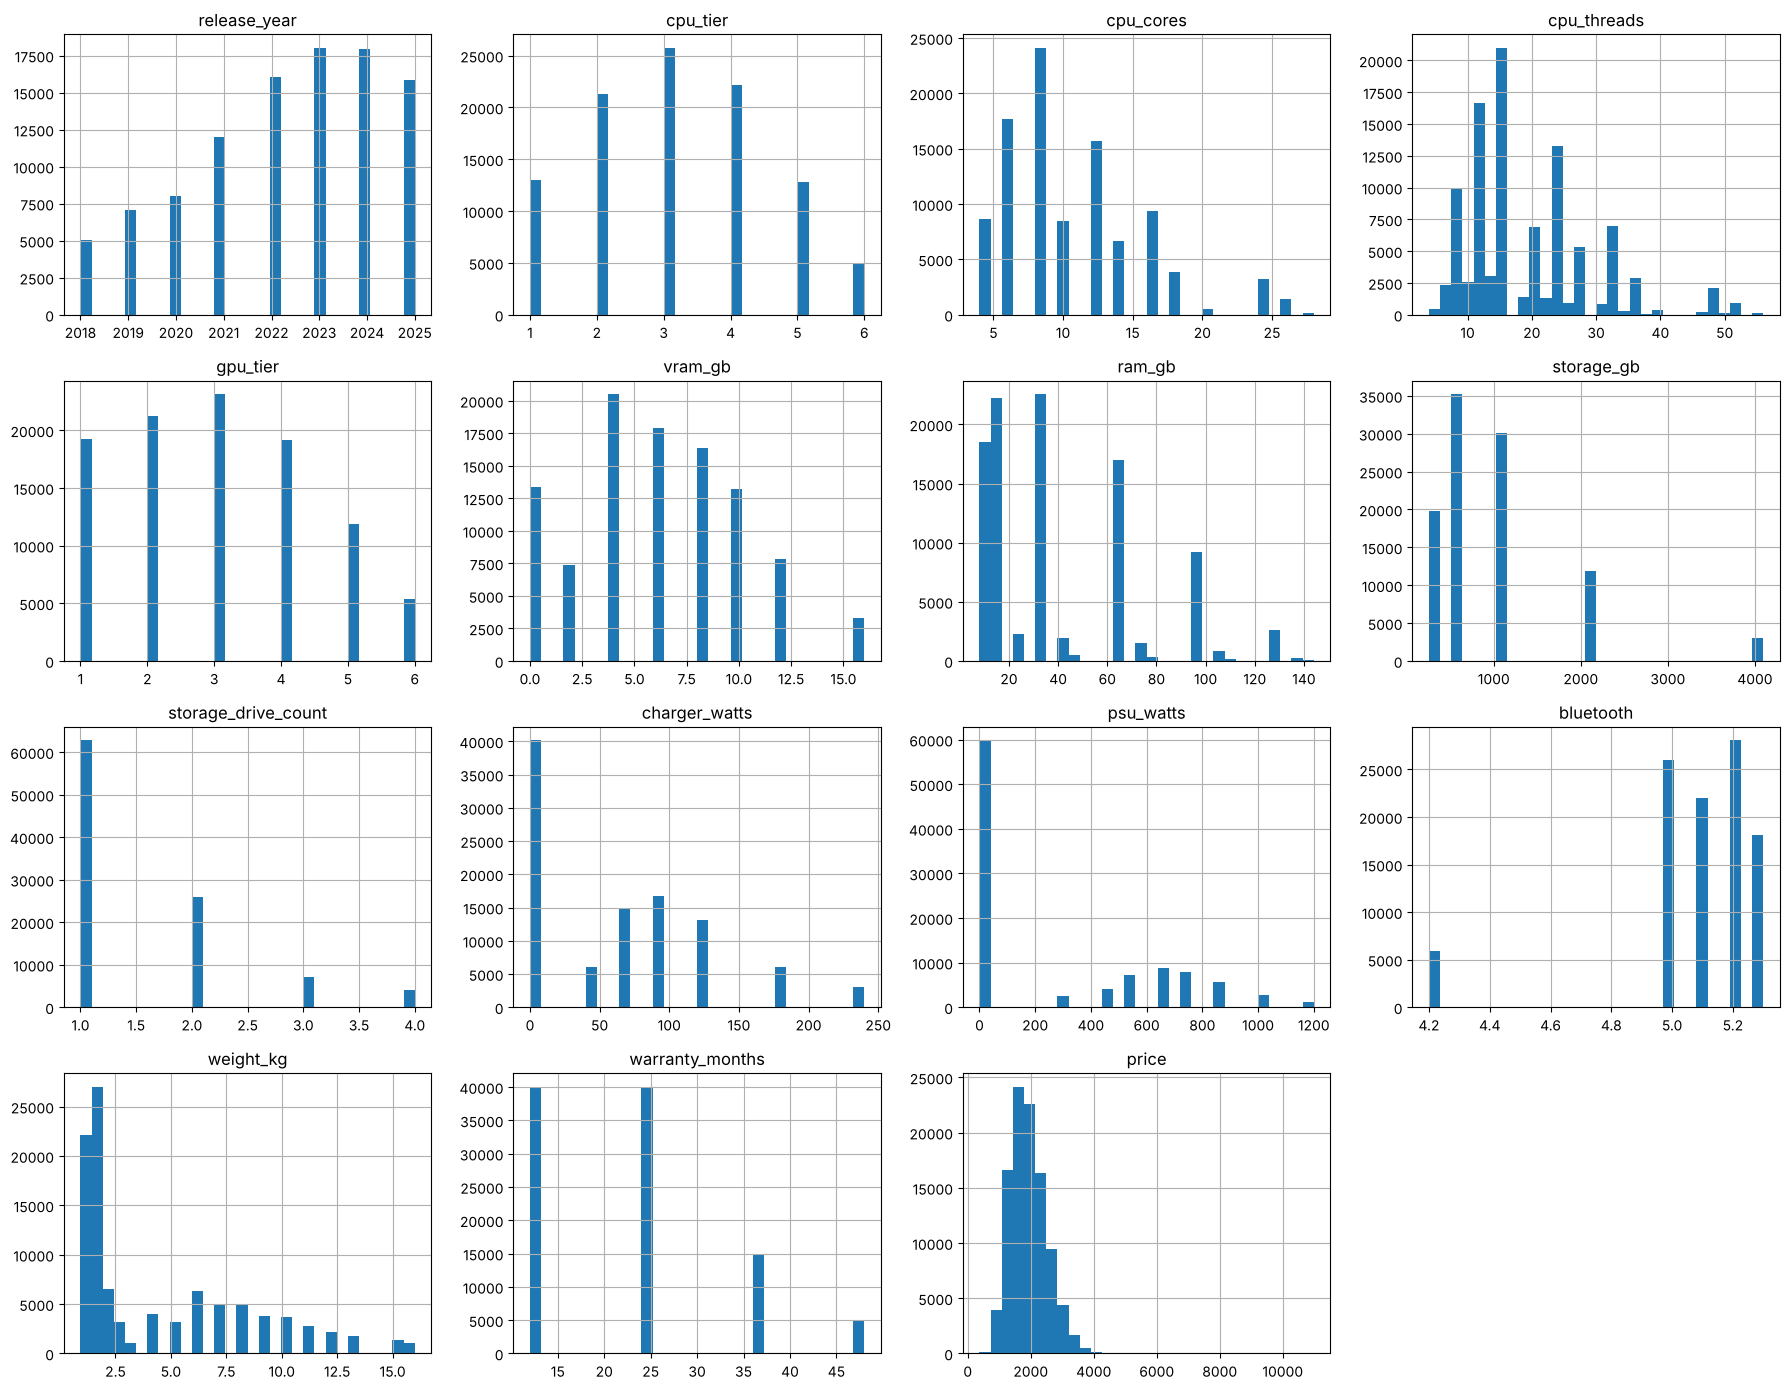

In [10]:
# Histogramas de las variables numéricas
compu_df[num_cols].hist(bins=30, figsize=(18, 14))
plt.tight_layout()
plt.show()

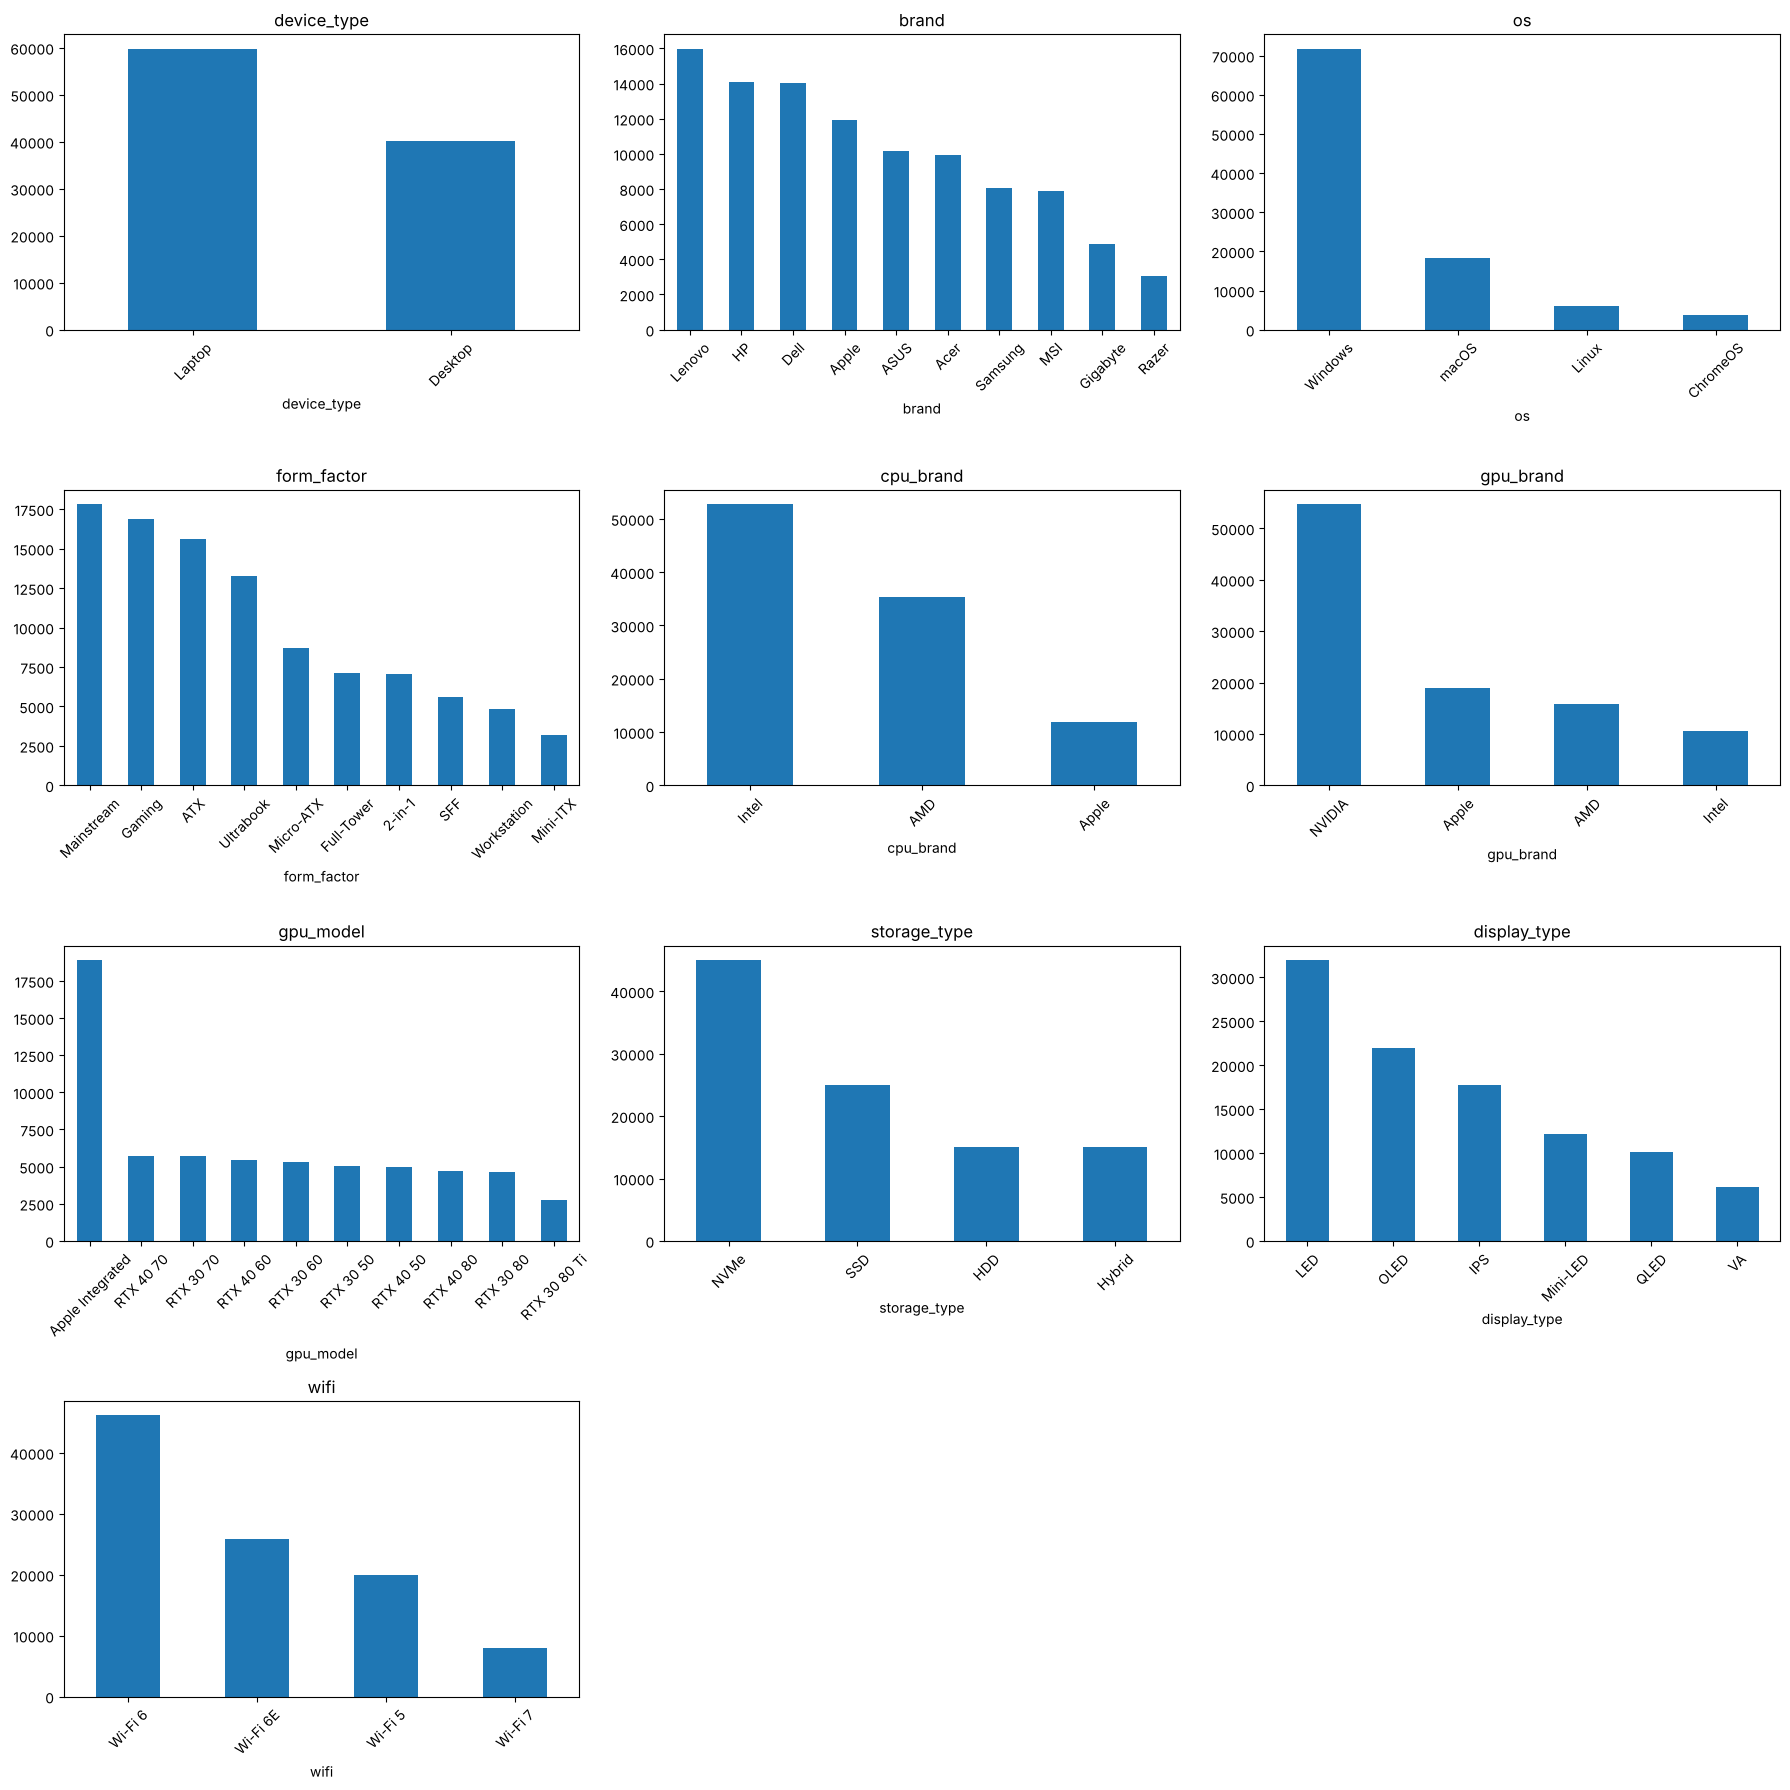

In [11]:
# Diagramas de barras de las variables categóricas (top 10 si hay alta cardinalidad)
fig, axes = plt.subplots(4, 3, figsize=(18, 18))
axes = axes.flatten()
for ax, col in zip(axes, cat_cols):
    compu_df[col].value_counts().head(10).plot(kind='bar', ax=ax, title=col)
    ax.tick_params(axis='x', rotation=45)
for ax in axes[len(cat_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

Análisis: No existen registros duplicados ni valores faltantes, por lo que no es necesario imputar ni eliminar filas.

La variable price presenta un sesgo positivo, con una cola larga hacia la derecha y valores de hasta 11,000 aproximadamente. Lo mismo ocurre con weight_kg, donde predominan las laptops ligeras. Las variables charger_watts y psu_watts muestran una barra muy alta en 0, lo cual se analiza en el ejercicio 5. Varias variables numéricas son discretas, como cpu_tier, gpu_tier, vram_gb, storage_gb y warranty_months, por eso sus histogramas aparecen como barras separadas.

En las variables categóricas predominan las laptops (cerca del 60%), el sistema operativo Windows (cerca del 72%), NVIDIA como marca de GPU y el estándar Wi-Fi 6. La variable gpu_model tiene 49 categorías, y la más frecuente es Apple Integrated.

3. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Reflexiona sobre cuáles variables, de las que se imprimieron, representan de manera general la capacidad del hardware y mantenlas; elimina las demás por aportar información redundante.
* Incluye una breve justificación de tus decisiones.

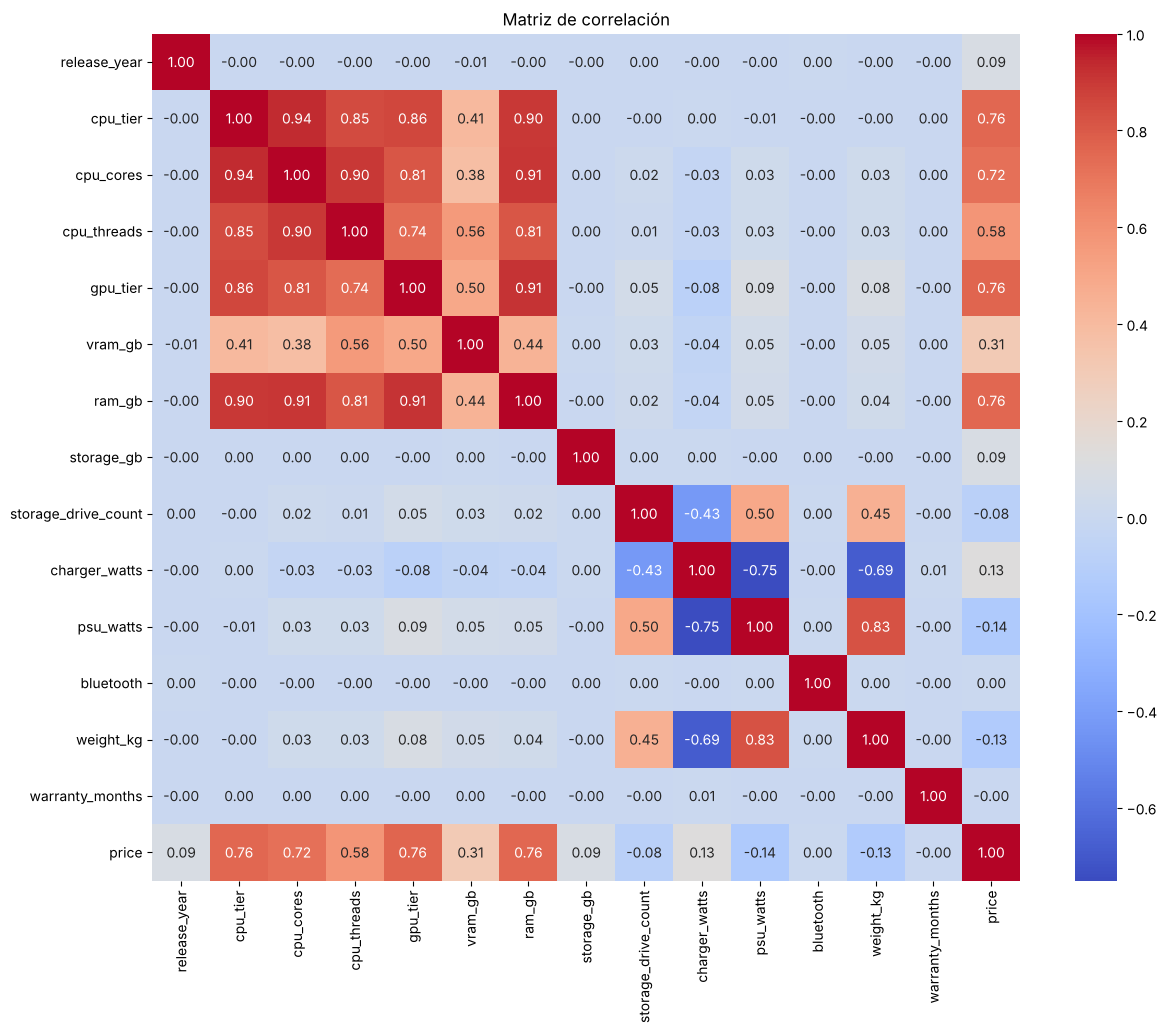

In [12]:
corr = compu_df[num_cols].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriz de correlación')
plt.show()

In [13]:
# Pares con correlación superior a 0.9
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pares[pares.abs() > 0.9])

cpu_tier   cpu_cores    0.937376
cpu_cores  ram_gb       0.906770
gpu_tier   ram_gb       0.912918
dtype: float64


Justificación: Los pares con correlación superior a 0.9 son cpu_tier con cpu_cores, cpu_cores con ram_gb, y gpu_tier con ram_gb. Se conservan cpu_tier y gpu_tier porque son indicadores ordinales que resumen de manera general la capacidad del procesador y de la tarjeta gráfica, ya que la gama refleja implícitamente los núcleos y la memoria. Se eliminan cpu_cores y ram_gb porque su información es redundante con estos niveles. Además, al quitarlas desaparecen los tres pares altamente correlacionados, con lo que se reduce la multicolinealidad.

In [14]:
compu_df = compu_df.drop(columns=['cpu_cores', 'ram_gb'])
compu_df.columns

Index(['device_type', 'brand', 'release_year', 'os', 'form_factor',
       'cpu_brand', 'cpu_tier', 'cpu_threads', 'gpu_brand', 'gpu_model',
       'gpu_tier', 'vram_gb', 'storage_type', 'storage_gb',
       'storage_drive_count', 'display_type', 'charger_watts', 'psu_watts',
       'wifi', 'bluetooth', 'weight_kg', 'warranty_months', 'price'],
      dtype='object')

4. Para comenzar con la ingeniería de características, crea una copia del dataframe y asígnala a un nuevo objeto llamado `compu_transf`.
* Calcula cuántos años han pasado desde el lanzamiento de cada computadora y almacénalo en una nueva columna llamada `years_since_release`; luego, elimina la columna original.
* Utiliza `KBinsDiscretizer` para reemplazar la columna `vram_gb` en 4 bins ordinales basados en cuantiles.
* Imprime los valores que delimitan cada bin y haz un gráfico de barras para ver la cantidad de observaciones en cada uno, con el fin de entender cómo se agruparon los datos.

In [15]:
compu_transf = compu_df.copy()

compu_transf['years_since_release'] = date.today().year - compu_transf['release_year']
compu_transf = compu_transf.drop(columns='release_year')
compu_transf['years_since_release'].value_counts().sort_index()

years_since_release
1    15835
2    17969
3    18020
4    16054
5    12016
6     7986
7     7090
8     5030
Name: count, dtype: int64

Límites de los bins: [ 0.  4.  6.  8. 16.]


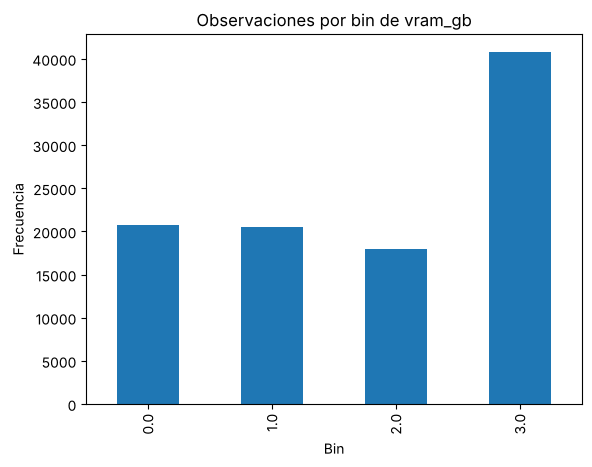

In [16]:
kbins = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
compu_transf['vram_gb'] = kbins.fit_transform(compu_transf[['vram_gb']])
print('Límites de los bins:', kbins.bin_edges_[0])

compu_transf['vram_gb'].value_counts().sort_index().plot(kind='bar')
plt.title('Observaciones por bin de vram_gb')
plt.xlabel('Bin')
plt.ylabel('Frecuencia')
plt.show()

Análisis: Los límites de los bins son 0, 4, 6, 8 y 16 GB. Como vram_gb es una variable discreta con valores muy repetidos, los bins no quedan con el mismo número de observaciones. El último bin, de 8 a 16 GB, agrupa alrededor de 40,800 registros, mientras que los tres primeros tienen entre 18,000 y 21,000 registros cada uno, aproximadamente.

5. Observa los histogramas del ejercicio 2. Notarás que en las variables `charger_watts` y `psu_watts` aparece una barra en 0. Analiza por qué ocurre esto y qué significa en relación con el tipo de dispositivo.
* Como estas variables son mutuamente excluyentes, combínalas en una nueva columna llamada `power_watts` que contenga la potencia correspondiente de cada dispositivo y, a continuación, haz un histograma para verificar que la distribución resultante es bimodal.
* Por último, borra las columnas originales `charger_watts` y `psu_watts`.

In [17]:
pd.crosstab(compu_transf['device_type'],
            [compu_transf['charger_watts'] == 0, compu_transf['psu_watts'] == 0],
            rownames=['device_type'], colnames=['charger_watts == 0', 'psu_watts == 0'])

charger_watts == 0,False,True
psu_watts == 0,True,False
device_type,,
Desktop,0,40156
Laptop,59844,0


Análisis: La tabla cruzada muestra que charger_watts vale 0 en todas las desktops y psu_watts vale 0 en todas las laptops. El 0 no es una potencia real ni un error, sino que indica que el atributo no aplica para ese tipo de dispositivo: las laptops usan cargador y las desktops usan una fuente de poder. Por eso ambas variables son mutuamente excluyentes y pueden combinarse en una sola.

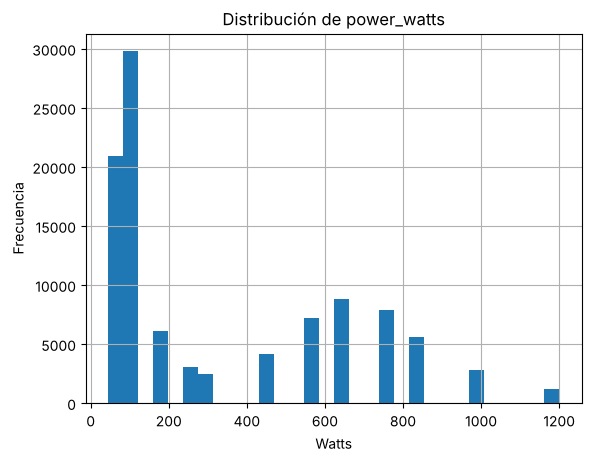

In [18]:
compu_transf['power_watts'] = compu_transf['charger_watts'] + compu_transf['psu_watts']
compu_transf = compu_transf.drop(columns=['charger_watts', 'psu_watts'])

compu_transf['power_watts'].hist(bins=30)
plt.title('Distribución de power_watts')
plt.xlabel('Watts')
plt.ylabel('Frecuencia')
plt.show()

Análisis: La distribución de power_watts es bimodal. El primer grupo se concentra entre 45 y 240 W aproximadamente y corresponde a los cargadores de las laptops. El segundo grupo va de 300 a 1,200 W aproximadamente y corresponde a las fuentes de poder de las desktops.

6. Para disminuir el sesgo de la variable `price`, crea tres transformadores: logaritmo, raíz cuadrada y Box - Cox.
* Aplica cada transformador a la variable price, dejando el resultado en variables temporales. El objetivo es comparar los efectos de cada transformación antes de decidir cuál aplicar de manera definitiva sobre las variables continuas del dataframe.
* De la variable original y de cada una de las tres transformaciones se debe mostrar:
  * Histograma: para observar la distribución de los datos.
  * Boxplot: para identificar posibles valores atípicos.
  * Q-Q plot: para evaluar la normalidad de la variable.
  * Skew (sesgo): para cuantificar la asimetría de la distribución.
  * Cantidad de outliers: para conocer cuántos valores extremos existen.
* En función de los resultados obtenidos al comparar las transformaciones, decide cuál logró el mejor efecto sobre la distribución de la variable y aplícala directamente en el dataframe, reemplazando las variables continuas: `weight_kg`, `power_watts` y `price`.

In [19]:
log_tf = FunctionTransformer(np.log)
sqrt_tf = FunctionTransformer(np.sqrt)
boxcox_tf = PowerTransformer(method='box-cox', standardize=False)

price_log = log_tf.fit_transform(compu_transf[['price']])
price_sqrt = sqrt_tf.fit_transform(compu_transf[['price']])
price_boxcox = boxcox_tf.fit_transform(compu_transf[['price']])

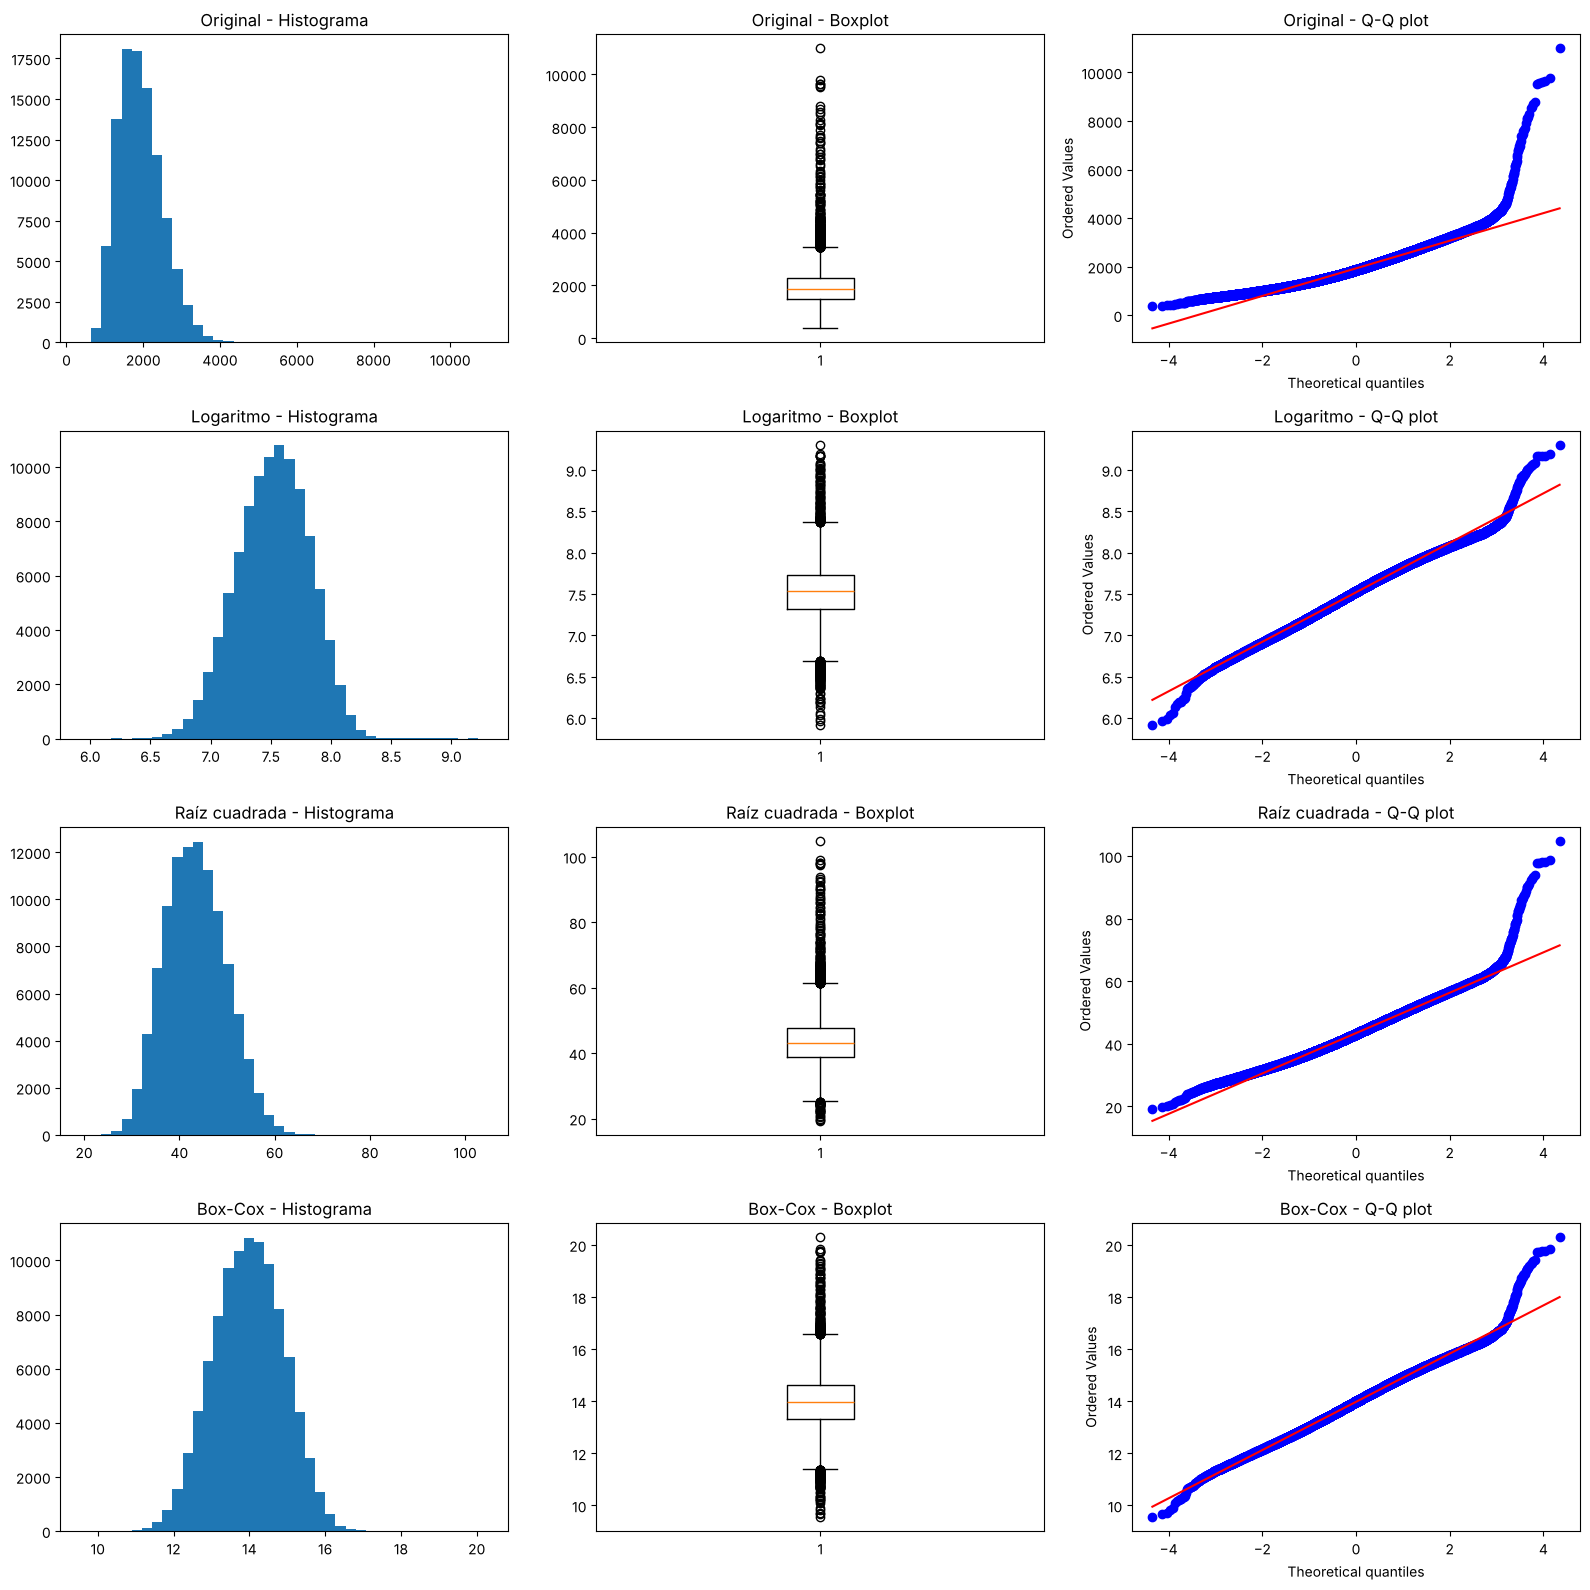

,Skew,Outliers
Original,0.986644,976
Logaritmo,-0.133105,386
Raíz cuadrada,0.332253,364
Box-Cox,-0.000238,317


In [20]:
def contar_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

versiones = {
    'Original': compu_transf['price'],
    'Logaritmo': pd.Series(np.ravel(price_log)),
    'Raíz cuadrada': pd.Series(np.ravel(price_sqrt)),
    'Box-Cox': pd.Series(np.ravel(price_boxcox)),
}

fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for i, (nombre, s) in enumerate(versiones.items()):
    axes[i, 0].hist(s, bins=40)
    axes[i, 0].set_title(f'{nombre} - Histograma')
    axes[i, 1].boxplot(s)
    axes[i, 1].set_title(f'{nombre} - Boxplot')
    probplot(s, dist='norm', plot=axes[i, 2])
    axes[i, 2].set_title(f'{nombre} - Q-Q plot')
plt.tight_layout()
plt.show()

pd.DataFrame({'Skew': [s.skew() for s in versiones.values()],
              'Outliers': [contar_outliers(s) for s in versiones.values()]},
             index=versiones.keys())

Decisión: La transformación Box-Cox logra el mejor efecto. Reduce el sesgo de 0.99 a prácticamente 0 (-0.0002), deja la menor cantidad de outliers (317 contra 976 de la variable original) y su Q-Q plot es el que más se ajusta a la recta de la distribución normal. El logaritmo también mejora la distribución, pero deja un ligero sesgo negativo (-0.13) y más outliers (386). La raíz cuadrada se queda corta, con un sesgo de 0.33. Por ello se aplica Box-Cox a weight_kg, power_watts y price.

In [21]:
continuas = ['weight_kg', 'power_watts', 'price']
compu_transf[continuas] = PowerTransformer(method='box-cox', standardize=False).fit_transform(compu_transf[continuas])
compu_transf[continuas].skew()

weight_kg      0.213748
power_watts    0.086581
price         -0.000238
dtype: float64

7. Para que todas las variables numéricas estén en la misma escala, aplica `MinMaxScaler` de sklearn a todas las columnas numéricas del dataframe, reemplazando las columnas originales.

In [22]:
num_cols = compu_transf.select_dtypes(include='number').columns
compu_transf[num_cols] = MinMaxScaler().fit_transform(compu_transf[num_cols])
compu_transf[num_cols].describe().T[['min', 'max']]

,min,max
cpu_tier,0.0,1.0
cpu_threads,0.0,1.0
gpu_tier,0.0,1.0
vram_gb,0.0,1.0
storage_gb,0.0,1.0
storage_drive_count,0.0,1.0
bluetooth,0.0,1.0
weight_kg,0.0,1.0
warranty_months,0.0,1.0
price,0.0,1.0


Comprobación: Todas las columnas numéricas quedaron con un valor mínimo de 0 y un máximo de 1.

8. Aunque `wifi` es una variable categórica, sus categorías tienen un orden natural (Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7). Codifícala usando `OrdinalEncoder`.
* Luego, escala la variable codificada entre 0 y 1 con `MinMaxScaler`, para que quede en la misma escala que las variables numéricas del dataframe.

Nota: Ambos cambios deben efectuarse sobre la columna original, de manera que quede una única columna `wifi` con toda la información transformada.

In [23]:
ordinal = OrdinalEncoder(categories=[['Wi-Fi 5', 'Wi-Fi 6', 'Wi-Fi 6E', 'Wi-Fi 7']])
compu_transf['wifi'] = ordinal.fit_transform(compu_transf[['wifi']])
compu_transf['wifi'] = MinMaxScaler().fit_transform(compu_transf[['wifi']])
compu_transf['wifi'].value_counts().sort_index()

wifi
0.000000    19926
0.333333    46149
0.666667    25923
1.000000     8002
Name: count, dtype: int64

Comprobación: La variable wifi quedó en una sola columna con los valores 0, 0.33, 0.67 y 1, respetando el orden Wi-Fi 5, Wi-Fi 6, Wi-Fi 6E y Wi-Fi 7.

9. La variable `gpu_model` tiene muchas categorías. Usar *One-Hot Encoding* aumentaría significativamente la dimensionalidad del dataframe. Por ello, utiliza `BinaryEncoder` para codificarla.
* Guarda el resultado en un dataframe llamado `bin_df`. Más adelante, lo combinarás con `compu_transf` para integrar las variables codificadas.

In [24]:
bin_encoder = BinaryEncoder(cols=['gpu_model'])
bin_df = bin_encoder.fit_transform(compu_transf[['gpu_model']])
bin_df.head()

,gpu_model_0,gpu_model_1,gpu_model_2,gpu_model_3,gpu_model_4,gpu_model_5
0,0,0,0,0,0,1
1,0,0,0,0,1,0
2,0,0,0,0,1,1
3,0,0,0,1,0,0
4,0,0,0,1,0,1


Comprobación: Con BinaryEncoder, las 49 categorías de gpu_model se representan con solo 6 columnas binarias, en lugar de las 48 columnas que generaría One-Hot Encoding con drop='first'.

10. Usa `OneHotEncoder` para codificar las variables categóricas restantes. Asegúrate de usar `drop='first'` para evitar la multicolinealidad y guarda el resultado en un dataframe llamado `ohe_df`
* Combina el dataframe `compu_transf` con las variables categóricas que fueron codificadas en `bin_df` y `ohe_df`. No olvides eliminar las variables originales.
* Usa `describe()` sobre el dataframe resultante para corroborar que todas las columnas estén escaladas entre 0 y 1 y que no queden variables categóricas sin codificar.

In [25]:
cat_cols = compu_transf.select_dtypes(include='object').columns.drop('gpu_model')
ohe = OneHotEncoder(drop='first', sparse_output=False)
ohe_df = pd.DataFrame(ohe.fit_transform(compu_transf[cat_cols]),
                      columns=ohe.get_feature_names_out(cat_cols),
                      index=compu_transf.index)
ohe_df.head()

,device_type_Laptop,brand_Acer,brand_Apple,brand_Dell,brand_Gigabyte,brand_HP,brand_Lenovo,brand_MSI,brand_Razer,brand_Samsung,...,gpu_brand_Intel,gpu_brand_NVIDIA,storage_type_Hybrid,storage_type_NVMe,storage_type_SSD,display_type_LED,display_type_Mini-LED,display_type_OLED,display_type_QLED,display_type_VA
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [26]:
compu_transf = pd.concat([compu_transf.drop(columns=list(cat_cols) + ['gpu_model']), bin_df, ohe_df], axis=1)
print(compu_transf.shape)
print('Columnas no numéricas:', list(compu_transf.select_dtypes(exclude='number').columns))
compu_transf.describe().T

(100000, 54)
Columnas no numéricas: []


,count,mean,std,min,25%,50%,75%,max
cpu_tier,100000.0,0.430698,0.274635,0.0,0.200000,0.400000,0.600000,1.0
cpu_threads,100000.0,0.295629,0.186893,0.0,0.153846,0.230769,0.384615,1.0
gpu_tier,100000.0,0.398270,0.291929,0.0,0.200000,0.400000,0.600000,1.0
vram_gb,100000.0,0.595883,0.394170,0.0,0.333333,0.666667,1.000000,1.0
storage_gb,100000.0,0.168733,0.201626,0.0,0.066667,0.066667,0.200000,1.0
storage_drive_count,100000.0,0.174993,0.265761,0.0,0.000000,0.000000,0.333333,1.0
wifi,100000.0,0.406670,0.284834,0.0,0.333333,0.333333,0.666667,1.0
bluetooth,100000.0,0.804331,0.223616,0.0,0.727273,0.818182,0.909091,1.0
weight_kg,100000.0,0.517032,0.293982,0.0,0.280423,0.417162,0.834353,1.0
warranty_months,100000.0,0.283343,0.284219,0.0,0.000000,0.333333,0.333333,1.0


Conclusión: El dataframe final tiene 100,000 registros y 54 columnas, todas numéricas y con valores entre 0 y 1, por lo que no quedan variables categóricas sin codificar. El conjunto de datos está listo para la etapa de modelado.

Declaración de uso de IA

Anthropic. (2026). Claude (Opus 5.5) [Modelo de lenguaje grande], utilizado para recomendaciones de código y depuración de errores. https://claude.ai/